In [1]:
   %%writefile physics.py
"""
Mekanika orbitale e nevojshme per problemin (zevendeson librarine pykep 2.x,
e cila nuk po me instalohet ne Kaggle).

  lambert()    - si arrihet nga pika r1 te pika r2 per kohen tof
  propagate()  - ku ndodhet anija pas kohes t ne orbite
  flyby()      - si ndryshon shpejtesia kur anija kalon prane nje planeti
  elements()   - gjysmeboshti a, ekscentriciteti e dhe anomalia E e nje orbite
  Planet       - pozita dhe shpejtesia e nje planeti ne nje date te caktuar

Vektoret jane tuple (x, y, z). Njesite: metra, sekonda.
"""
import math

AU = 149597870691.0          # njesia astronomike [m]
DAY = 86400.0                # nje dite [s]
EARTH_RADIUS = 6378137.0     # [m]


# ---------- veprime me vektore ----------
def dot(a, b):
    return a[0] * b[0] + a[1] * b[1] + a[2] * b[2]


def cross(a, b):
    return (a[1] * b[2] - a[2] * b[1], a[2] * b[0] - a[0] * b[2], a[0] * b[1] - a[1] * b[0])


def norm(a):
    return math.sqrt(dot(a, a))


def sub(a, b):
    return (a[0] - b[0], a[1] - b[1], a[2] - b[2])


def mul(a, k):
    return (a[0] * k, a[1] * k, a[2] * k)


def comb(a, ka, b, kb):
    """ka*a + kb*b"""
    return (ka * a[0] + kb * b[0], ka * a[1] + kb * b[1], ka * a[2] + kb * b[2])


NAN3 = (float("nan"),) * 3


# ---------- elementet e orbites ----------
def elements(r, v, mu):
    """Kthen (a, e, E) si ne pykep: a gjithmone pozitiv, E = anomalia e ekscentrike
    (ose ekuivalenti per hiperbole). NaN per orbita te degjeneruara."""
    try:
        h = cross(r, v)
        p = dot(h, h) / mu
        R = norm(r)
        vh = cross(v, h)
        ev = (vh[0] / mu - r[0] / R, vh[1] / mu - r[1] / R, vh[2] / mu - r[2] / R)
        e = norm(ev)
        a = abs(p / (1 - e * e))
        c = dot(ev, r) / e / R
        nu = math.acos(c) if -1 <= c <= 1 else float("nan")   # anomalia e vertete
        if dot(r, v) < 0:
            nu = 2 * math.pi - nu
        k = math.sqrt(abs((1 - e) / (1 + e)))
        E = 2 * math.atan(k * math.tan(nu / 2))
        return a, e, E
    except (ZeroDivisionError, ValueError):
        return float("nan"), float("nan"), float("nan")


# ---------- propagimi ne orbite (ekuacioni i Keplerit) ----------
def propagate(r0, v0, t, mu):
    """Pozita dhe shpejtesia pas t sekondash. Ngre RuntimeError nese deshton."""
    try:
        R = norm(r0)
        V = norm(v0)
        a = -mu / (V * V - 2 * mu / R)          # gjysmeboshti (negativ per hiperbole)
        s0 = dot(r0, v0) / math.sqrt(mu)
        if a > 0:   # elipse: zgjidhim per ndryshimin e anomalise x
            n = math.sqrt(mu / a ** 3) * t
            f = lambda x: x - n + s0 / math.sqrt(a) * (1 - math.cos(x)) - (1 - R / a) * math.sin(x)
            x = bisect(f, n - 4, n + 4)
            c, s = math.cos(x), math.sin(x)
            G = a * s0 / math.sqrt(mu) * (1 - c) + R * math.sqrt(a / mu) * s
            r = a + (R - a) * c + s0 * math.sqrt(a) * s
            Ft = -math.sqrt(mu * a) / (r * R) * s
        else:       # hiperbole
            n = math.sqrt(-mu / a ** 3) * t
            f = lambda x: -x - n + s0 / math.sqrt(-a) * (math.cosh(x) - 1) + (1 - R / a) * math.sinh(x)
            lo, hi = -1.0, 1.0
            while f(lo) > 0:
                lo *= 2
            while f(hi) < 0:
                hi *= 2
            x = bisect(f, lo, hi)
            c, s = math.cosh(x), math.sinh(x)
            G = a * s0 / math.sqrt(mu) * (1 - c) + R * math.sqrt(-a / mu) * s
            r = a + (R - a) * c + s0 * math.sqrt(-a) * s
            Ft = -math.sqrt(-mu * a) / (r * R) * s
        F = 1 - a / R * (1 - c)
        Gt = 1 - a / r * (1 - c)
        return comb(r0, F, v0, G), comb(r0, Ft, v0, Gt)
    except (ZeroDivisionError, OverflowError, ValueError) as err:
        raise RuntimeError(err)


def bisect(f, lo, hi, iters=100):
    """Rrenja e nje funksioni rrites f ne [lo, hi] me metoden e pergjysmimit."""
    for _ in range(iters):
        mid = (lo + hi) / 2
        if f(mid) > 0:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2


# ---------- problemi i Lambert-it (algoritmi i Izzo, 2015) ----------
def lambert(r1, r2, tof, mu):
    """Shpejtesia ne nisje dhe ne mberritje per te shkuar nga r1 te r2 per tof sekonda
    (0 rrotullime, drejtimi prograd). Kthen NaN nese nuk ka zgjidhje."""
    try:
        c = norm(sub(r2, r1))
        n1, n2 = norm(r1), norm(r2)
        s = (n1 + n2 + c) / 2
        i1, i2 = mul(r1, 1 / n1), mul(r2, 1 / n2)
        ih = cross(i1, i2)
        ih = mul(ih, 1 / norm(ih))
        lam = math.sqrt(max(0.0, 1 - c / s))
        if ih[2] < 0:                        # kendi i transferit > 180 grade
            lam = -lam
            t1, t2 = cross(i1, ih), cross(i2, ih)
        else:
            t1, t2 = cross(ih, i1), cross(ih, i2)
        T = math.sqrt(2 * mu / s ** 3) * tof
        x = _solve_x(lam, T)
        y = math.sqrt(1 - lam * lam * (1 - x * x))
        g = math.sqrt(mu * s / 2)
        rho = (n1 - n2) / c
        sig = math.sqrt(1 - rho * rho)
        vr1 = g * ((lam * y - x) - rho * (lam * y + x)) / n1
        vr2 = -g * ((lam * y - x) + rho * (lam * y + x)) / n2
        vt = g * sig * (y + lam * x)
        return comb(i1, vr1, t1, vt / n1), comb(i2, vr2, t2, vt / n2)
    except (ZeroDivisionError, OverflowError, ValueError, RuntimeError):
        return NAN3, NAN3


def _tof(x, lam):
    """Koha (pa dimension) e transferit si funksion i variablit x."""
    y = math.sqrt(1 - lam * lam * (1 - x * x))
    if 0.77 < x < 1.18:                      # afer parabolës: seri hipergjeometrike
        eta = y - lam * x
        z = (1 - lam - x * eta) / 2
        q, term, k = 1.0, 1.0, 0
        while True:
            term *= (3 + k) * (1 + k) / (2.5 + k) * z / (k + 1)
            if q + term == q:
                break
            q += term
            k += 1
        return (eta ** 3 * 4 / 3 * q + 4 * lam * eta) / 2
    if x < 1:
        psi = math.acos(max(-1.0, min(1.0, x * y + lam * (1 - x * x))))
    else:
        psi = math.asinh((y - x * lam) * math.sqrt(x * x - 1))
    return (psi / math.sqrt(abs(1 - x * x)) - x + lam * y) / (1 - x * x)


def _solve_x(lam, T):
    """Gjen x qe _tof(x) = T me metoden e Newton-it (derivati numerik)."""
    T00 = math.acos(lam) + lam * math.sqrt(1 - lam * lam)
    T1 = 2 / 3 * (1 - lam ** 3)
    if T >= T00:
        x = -(T - T00) / (T - T00 + 4)
    elif T <= T1:
        x = T1 * (T1 - T) / (0.4 * (1 - lam ** 5) * T) + 1
    else:
        x = (T / T00) ** (math.log(2) / math.log(T1 / T00)) - 1
    for _ in range(60):
        h = 1e-7
        f = _tof(x, lam) - T
        d = (_tof(x + h, lam) - _tof(x - h, lam)) / (2 * h)
        x_new = x - f / d
        if x_new <= -1:
            x_new = (x - 1) / 2
        if abs(x_new - x) < 1e-12:
            return x_new
        x = x_new
    raise RuntimeError("Lambert nuk konvergjoi")


# ---------- fly-by ----------
def flyby(v, v_pla, rp, beta, mu):
    """Shpejtesia pas kalimit prane planetit (rp = distanca minimale, beta = kendi i planit)."""
    vr = sub(v, v_pla)
    vn = norm(vr)
    delta = 2 * math.asin(1 / (1 + rp * vn * vn / mu))      # kendi i kthimit
    i = mul(vr, 1 / vn)
    j = cross(i, v_pla)
    j = mul(j, 1 / norm(j))
    k = cross(i, j)
    cd, sd = math.cos(delta), math.sin(delta)
    cb, sb = math.cos(beta), math.sin(beta)
    return tuple(v_pla[m] + vn * (cd * i[m] + cb * sd * j[m] + sb * sd * k[m]) for m in range(3))


# ---------- planetet ----------
class Planet:
    def __init__(self, t_ref, a, e, i, W, w, M0, mu_star, mu_self):
        self.t_ref, self.a, self.e, self.i, self.W, self.w, self.M0 = t_ref, a, e, i, W, w, M0
        self.mu_star, self.mu_self = mu_star, mu_self
        self.radius = EARTH_RADIUS
        self.n = math.sqrt(mu_star / a ** 3)            # levizja mesatare [rad/s]

    def eph(self, t_days):
        """Pozita dhe shpejtesia ne daten t (dite nga 2000-01-01)."""
        M = (self.M0 + self.n * (t_days - self.t_ref) * DAY) % (2 * math.pi)
        E = M
        for _ in range(30):                              # ekuacioni i Keplerit M = E - e sin E
            E -= (E - self.e * math.sin(E) - M) / (1 - self.e * math.cos(E))
        a, e = self.a, self.e
        b = a * math.sqrt(1 - e * e)
        x, y = a * (math.cos(E) - e), b * math.sin(E)
        k = self.n / (1 - e * math.cos(E))
        vx, vy = -a * k * math.sin(E), b * k * math.cos(E)
        cW, sW, cw, sw = math.cos(self.W), math.sin(self.W), math.cos(self.w), math.sin(self.w)
        ci, si = math.cos(self.i), math.sin(self.i)
        R = ((cW * cw - sW * sw * ci, -cW * sw - sW * cw * ci),
             (sW * cw + cW * sw * ci, -sW * sw + cW * cw * ci),
             (sw * si, cw * si))
        return (tuple(R[m][0] * x + R[m][1] * y for m in range(3)),
                tuple(R[m][0] * vx + R[m][1] * vy for m in range(3)))


Writing physics.py


In [2]:
%%writefile problem.py
"""
Problemi Trappist Tour (ESA SpOC 2022): te dhenat e planeteve dhe funksioni fitness.

Vektori x (34 vlera):
  x[0:3]          u, v, T0                hyrja ne sistem (drejtimi + kohezgjatja)
  x[3:27]         6 x [beta, rp, eta, T]  per cdo hap planet -> planet
  x[27:34]        s0..s6                  renditja e planeteve (0..6 = b..h)

fitness(x) -> (DV, T, eq, ineq) njesoj si kodi zyrtar i ESA-s.

Funksioni eshte ndare ne HAPA (legs): kostoja e hapit k varet vetem nga
gjendja e anijes kur arrin te planeti k dhe nga 4 parametrat e hapit.
Kete e shfrytezon algoritmi (solver.py).
"""
import math
from physics import AU, DAY, Planet, lambert, propagate, flyby, elements, norm, sub

# ---------- konstantet (nga kodi zyrtar) ----------
G = 6.67430e-11
MU = G * 8.98266512e-2 * 1.989e30          # parametri gravitacional i yllit TRAPPIST-1
SAFE_RADIUS = 10 * 83484000.0              # distanca minimale nga ylli [m]
T_START = 7000.0                           # 2019-03-02 ne dite nga 2000-01-01
R_START = 10 * AU                          # anija nis ne sferen 10 AU
V_START = 1e4                              # me shpejtesi 10 km/s
NAMES = "bcdefgh"
INF = float("inf")

_mass = [1.36004499, 1.29688971, 0.38588417, 0.688627613, 1.03510927, 1.31679654, 0.320988718]
_a = [0.01154035, 0.0158073, 0.02226718, 0.02926548, 0.0385054, 0.04683828, 0.06191385]
_e = [0.00455247, 0.00107698, 0.00624362, 0.00577129, 0.00861154, 0.00400202, 0.00378361]
_i = [1.1, 1.3, 0.5, -0.3, 0.01, 1.2, 2.3]
_W = [238.35940145, 221.02196847, 90.26523049, 164.16001523, 171.42668515, 166.63349296, 282.808809]
_w = [126.22225948, 80.78036351, 147.44525146, 315.09376191, 179.82855007, 25.31242216, 176.19682451]
_M = [33.40998384, -89.79506054, -28.38482427, 45.00185452, -145.16404128, 12.59883066, -12.12072197]
D2R = math.pi / 180
PLANETS = [Planet(T_START, _a[k] * AU, _e[k], _i[k] * D2R, _W[k] * D2R, _w[k] * D2R, _M[k] * D2R,
                  MU, G * _mass[k] * 5.9722e24) for k in range(7)]

# kufijte e variablave
LEG_LB = [0.0, 1.1, 0.001, 5.0]                 # beta, rp, eta, T
LEG_UB = [2 * math.pi, 100.0, 0.999, 2000.0]
LB = [0.0, 0.25, 5.0] + LEG_LB * 6 + [0] * 7
UB = [1.0, 0.75, 2000.0] + LEG_UB * 6 + [6] * 7


def distance_violation(r, v, t_days):
    """A i afrohet anija yllit me shume se SAFE_RADIUS gjate t_days?
    Kthen > 0 nese po (shkelje), perndryshe nje numer negativ."""
    a, e, E0 = elements(r, v, MU)
    if not (math.isfinite(a) and math.isfinite(e)):
        return 1e17
    rp = a * abs(1 - e)                           # distanca me e vogel e orbites (periapsis)
    try:
        r2, v2 = propagate(r, v, t_days * DAY, MU)
    except RuntimeError:
        return 1e17
    period = 2 * math.pi * math.sqrt(a ** 3 / MU) / DAY
    E = elements(r2, v2, MU)[2]
    # a e kaloi anija periapsis-in gjate kesaj kohe? (njesoj si kodi zyrtar)
    if t_days > period:
        passed = True
    elif E0 > 0:
        passed = 0 < E < E0
    else:
        passed = E > 0 or t_days > period / 2
    return SAFE_RADIUS - rp if passed else -1e17


class State:
    """Gjendja e anijes kur arrin te nje planet."""
    def __init__(self, planet, t, r, v_planet, v_in):
        self.planet, self.t, self.r, self.v_planet, self.v_in = planet, t, r, v_planet, v_in


def entry_leg(u, v, T0, planet):
    """Hapi hyres: nga sfera 10 AU te planeti i pare. Kthen (DV, shkelja, State)."""
    th, ph = 2 * math.pi * u, math.acos(2 * v - 1) - math.pi / 2
    r0 = (R_START * math.cos(ph) * math.cos(th), R_START * math.cos(ph) * math.sin(th), R_START * math.sin(ph))
    t = T_START + T0
    rP, vP = PLANETS[planet].eph(t)
    v1, v2 = lambert(r0, rP, T0 * DAY, MU)
    if math.isnan(v1[0]):
        return INF, INF, None
    dv = abs(norm(v1) - V_START)           # anija tashme leviz me 10 km/s
    return dv, distance_violation(r0, v1, T0), State(planet, t, rP, vP, v2)


def next_leg(st, beta, rp, eta, T, planet):
    """Fly-by te planeti aktual, udhetim i lire eta*T dite, manover (DSM),
    pastaj harku Lambert deri te planeti tjeter. Kthen (DV, shkelja, State)."""
    p = PLANETS[st.planet]
    v_out = flyby(st.v_in, st.v_planet, rp * p.radius, beta, p.mu_self)
    viol = distance_violation(st.r, v_out, eta * T)
    try:
        r, v = propagate(st.r, v_out, eta * T * DAY, MU)
    except RuntimeError:
        return INF, INF, None
    t = st.t + T
    rP, vP = PLANETS[planet].eph(t)
    v1, v2 = lambert(r, rP, (1 - eta) * T * DAY, MU)
    if math.isnan(v1[0]):
        return INF, INF, None
    viol = max(viol, distance_violation(r, v1, (1 - eta) * T))
    return norm(sub(v1, v)), viol, State(planet, t, rP, vP, v2)


def fitness(x):
    """(DV totale [m/s], koha totale [dite], eq, ineq) – eq == 0 dhe ineq <= 0 => e pranueshme."""
    seq = [int(s) for s in x[27:34]]
    eq = len(set(seq)) - 7
    T = sum(x[2:27:4])
    dv, viol, st = entry_leg(x[0], x[1], x[2], seq[0])
    for k in range(6):
        if st is None:
            return 1e10, T, eq, 1e17
        b = 3 + 4 * k
        d, vk, st = next_leg(st, x[b], x[b + 1], x[b + 2], x[b + 3], seq[k + 1])
        dv += d
        viol = max(viol, vk)
    if st is None:
        return 1e10, T, eq, 1e17
    return dv, T, eq, viol


def example():
    """Zgjidhja shembull nga ESA (DV = 2379 m/s, T = 3470 dite)."""
    return [0.829814333836995, 0.49439092971262544, 1501.6919241751443,
            1.5873030906083387, 1.512021386175137, 0.23024558713584858, 255.87994897371408,
            4.161192563429589, 8.278275659200725, 0.10265621329161562, 318.6140876998619,
            4.546432641418882, 4.078585717496654, 0.33605586368271645, 374.6287841767241,
            0.9461693914845313, 19.13985248269904, 0.4834964750829982, 343.8204904698013,
            2.1935168149524964, 32.48727508444479, 0.40957309270588427, 325.1537638293067,
            4.743610880353654, 49.95062395827792, 0.3668039400426466, 350.0377039343523,
            0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


def describe(x):
    """Shtyp nje permbledhje te tour-it."""
    seq = [int(s) for s in x[27:34]]
    dv, T, eq, ineq = fitness(x)
    print("Renditja:", " -> ".join(NAMES[s] for s in seq))
    print(f"DV totale = {dv:.1f} m/s, koha totale = {T:.1f} dite, e pranueshme = {eq == 0 and ineq <= 0}")


Writing problem.py


In [3]:
import problem
x = problem.example()
problem.describe(x)

Renditja: b -> c -> d -> e -> f -> g -> h
DV totale = 2379.0 m/s, koha totale = 3469.8 dite, e pranueshme = True


In [4]:
%%writefile solver.py
"""
Algoritmi:

1. BEAM SEARCH mbi renditjen e planeteve (pjesa kombinatorike, 7! = 5040 renditje).
   Tour-i nderohet hap pas hapi. Ne cdo nivel, per cdo tour te pjesshem provojme
   cdo planet te pavizituar si destinacion te radhes dhe ruajme vetem `width`
   tour-et me te lira (me DV me te vogel).
2. DIFFERENTIAL EVOLUTION (scipy) per 4 parametrat e vazhdueshem te cdo hapi.
3. Kohen e cdo hapi e kufizojme me T <= tcap. Per vlera te ndryshme te tcap
   marrim tour-e me te shpejte (DV me e madhe) ose me te ngadalte (DV me e vogel).
4. FRONTI PARETO i te gjitha tour-eve + HYPERVOLUME (pika referuese [2500, 4000]).
"""
import json
import math
from scipy.optimize import differential_evolution

import problem as P

REF = (2500.0, 4000.0)      # pika referuese e ESA-s
LAM = 0.5                   # sa "kushton" nje dite kohe [m/s per dite]


def optimize_entry(planet, seed):
    """Hapi hyres me DV minimale (T0 rreth 1500 dite, kur hyrja eshte pothuajse falas)."""
    def f(z):
        dv, viol, _ = P.entry_leg(z[0], z[1], z[2], planet)
        return dv + (1e7 if viol > 0 else 0)
    res = differential_evolution(f, [(0, 1), (0.25, 0.75), (1400, 1600)],
                                 maxiter=60, popsize=10, seed=seed, polish=False, tol=0)
    dv, viol, st = P.entry_leg(*res.x, planet)
    return dv, list(res.x), st


def optimize_leg(state, planet, tcap, seed):
    """4 parametrat [beta, rp, eta, T] te hapit, me T <= tcap."""
    def f(z):
        dv, viol, _ = P.next_leg(state, z[0], z[1], z[2], z[3], planet)
        return dv + LAM * z[3] + (1e7 if viol > 0 else 0)
    bounds = list(zip(P.LEG_LB, P.LEG_UB))
    bounds[3] = (5.0, tcap)
    res = differential_evolution(f, bounds, maxiter=60, popsize=10, seed=seed, polish=False, tol=0)
    dv, viol, st = P.next_leg(state, *res.x, planet)
    if viol > 0:
        return math.inf, list(res.x), None
    return dv, list(res.x), st


def beam_search(tcap, width=8, seed=0):
    """Kthen listen e tour-eve te plota: (DV, T, x)."""
    # niveli 1: nje tour i pjesshem per cdo planet te pare
    beam = []                               # elementet: (DV, x, state, renditja)
    for p in range(7):
        dv, x, st = optimize_entry(p, seed + p)
        beam.append((dv, x, st, [p]))
    # nivelet 2..7: shtojme nga nje planet
    for level in range(6):
        children = []
        for i, (dv, x, st, seq) in enumerate(beam):
            for p in range(7):
                if p in seq:
                    continue
                d, z, st2 = optimize_leg(st, p, tcap, seed + 100 * level + 10 * i + p)
                if st2 is not None:
                    children.append((dv + d, x + z, st2, seq + [p]))
        children.sort(key=lambda c: c[0])
        beam = children[:width]             # ruajme vetem me te mirat
    tours = []
    for dv, x, st, seq in beam:
        full = x + [float(s) for s in seq]
        f = P.fitness(full)
        if f[2] == 0 and f[3] <= 0:
            tours.append((f[0], f[1], full))
    return tours


def pareto_front(tours):
    """Zgjidhjet jo-te-dominuara (asnje tjeter nuk eshte me e mire ne te dy objektivat)."""
    front, best_T = [], math.inf
    for dv, T, x in sorted(tours):          # renditur sipas DV
        if T < best_T:
            front.append((dv, T, x))
            best_T = T
    return front


def hypervolume(points):
    """Siperfaqja e dominuar nga pikat deri te pika referuese (2 objektiva)."""
    pts = [(dv, T) for dv, T, *_ in points if dv < REF[0] and T < REF[1]]
    hv, prev_T = 0.0, REF[1]
    for dv, T in sorted(pts):
        if T < prev_T:
            hv += (REF[0] - dv) * (prev_T - T)
            prev_T = T
    return hv


def save_submission(front, path="submission.json"):
    xs = [x for dv, T, x in front if dv < REF[0] and T < REF[1]][:100]
    with open(path, "w") as fh:
        json.dump([{"decisionVector": xs, "problem": "trappist-tour",
                    "challenge": "spoc-trappist-tour"}], fh)
    return len(xs)


Writing solver.py


In [5]:
%%writefile tests.py
"""
Testet e projektit. Ekzekutohen me:   python tests.py
Nese te gjitha kalojne, shfaqet "Te gjitha testet kaluan".
"""
import math
import problem
import physics
import solver


def test_shembulli_esa():
    """Shembulli zyrtar i ESA-s duhet te jape DV = 2379 m/s dhe T = 3470 dite."""
    dv, T, eq, ineq = problem.fitness(problem.example())
    assert abs(dv - 2378.99) < 0.1, dv
    assert abs(T - 3469.83) < 0.1, T
    assert eq == 0 and ineq <= 0          # zgjidhja eshte e pranueshme
    print("OK  shembulli i ESA-s:", round(dv, 1), "m/s,", round(T, 1), "dite")


def test_lambert():
    """Anija qe niset me shpejtesine e Lambert-it duhet te arrije te planeti i synuar."""
    r1, _ = problem.PLANETS[0].eph(8000)          # planeti b
    r2, _ = problem.PLANETS[3].eph(8010)          # planeti e, 10 dite me vone
    v1, _ = physics.lambert(r1, r2, 10 * physics.DAY, problem.MU)
    r_arrives, _ = physics.propagate(r1, v1, 10 * physics.DAY, problem.MU)
    gabimi = physics.norm(physics.sub(r_arrives, r2))
    assert gabimi < 1000, gabimi                  # me pak se 1 km gabim
    print("OK  Lambert: gabimi ne mberritje =", round(gabimi, 3), "m")


def test_flyby():
    """Fly-by nuk e ndryshon madhesine e shpejtesise relative ndaj planetit."""
    p = problem.PLANETS[2]
    v_in, v_pla = (90e3, 5e3, 1e3), (80e3, 0.0, 0.0)
    v_out = physics.flyby(v_in, v_pla, 2 * p.radius, 1.0, p.mu_self)
    para = physics.norm(physics.sub(v_in, v_pla))
    pas = physics.norm(physics.sub(v_out, v_pla))
    assert abs(para - pas) < 1e-6
    print("OK  fly-by ruan shpejtesine relative:", round(para), "m/s")


def test_renditja_e_gabuar():
    """Nese nje planet perseritet, kufizimi eq duhet te jete i shkelur."""
    x = problem.example()
    x[27:34] = [0, 0, 2, 3, 4, 5, 6]              # planeti b dy here
    assert problem.fitness(x)[2] != 0
    print("OK  renditja e gabuar zbulohet")


def test_pareto():
    """Fronti Pareto mban vetem zgjidhjet qe nuk dominohen."""
    tours = [(1000, 3000, "A"), (2000, 2000, "B"), (1500, 3500, "C"), (900, 3900, "D")]
    front = solver.pareto_front(tours)
    emrat = [t[2] for t in front]
    assert emrat == ["D", "A", "B"], emrat       # C dominohet nga A
    print("OK  fronti Pareto:", emrat)


def test_hypervolume():
    """Hypervolume = siperfaqja e dominuar deri te pika referuese [2500, 4000]."""
    assert solver.hypervolume([(1500, 3000)]) == 1000 * 1000
    assert solver.hypervolume([(1000, 3000), (2000, 2000)]) == 1500 * 1000 + 500 * 1000
    assert solver.hypervolume([(3000, 1000)]) == 0          # jashte pikes referuese
    print("OK  hypervolume")


if __name__ == "__main__":
    test_shembulli_esa()
    test_lambert()
    test_flyby()
    test_renditja_e_gabuar()
    test_pareto()
    test_hypervolume()
    print("\nTe gjitha testet kaluan.")


Writing tests.py


In [6]:
!python tests.py

OK  shembulli i ESA-s: 2379.0 m/s, 3469.8 dite
OK  Lambert: gabimi ne mberritje = 0.0 m
OK  fly-by ruan shpejtesine relative: 11225 m/s
OK  renditja e gabuar zbulohet
OK  fronti Pareto: ['D', 'A', 'B']
OK  hypervolume

Te gjitha testet kaluan.


In [7]:
from multiprocessing import Pool
import time
import solver

start = time.time()
tcaps = [80, 100, 130, 160, 200, 250, 300, 400]   # kufiri i kohes per cdo hap (dite)

with Pool() as pool:
    results = pool.map(solver.beam_search, tcaps)

tours = [t for r in results for t in r]
front = solver.pareto_front(tours)

print("Tour-e te gjetura:", len(tours))
print("Zgjidhje ne frontin Pareto:", len(front))
print("Hypervolume:", round(solver.hypervolume(front)))
print("Koha:", round((time.time() - start) / 60, 1), "minuta")


Tour-e te gjetura: 64
Zgjidhje ne frontin Pareto: 22
Hypervolume: 3087029
Koha: 16.0 minuta


In [8]:
%%writefile plots.py
"""
Grafiket e rezultateve (me matplotlib).
  plot_pareto(front) - zgjidhjet: karburanti kundrejt kohes
  plot_tour(x)       - radha e planeteve qe viziton anija
"""
import math
import matplotlib.pyplot as plt
import problem
import solver

AU = 149597870691.0          # 1 njesi astronomike ne metra


def plot_pareto(front):
    # marrim vetem zgjidhjet brenda pikes referuese [2500, 4000]
    karburanti = [dv for dv, T, x in front if dv < 2500 and T < 4000]
    koha = [T for dv, T, x in front if dv < 2500 and T < 4000]

    plt.figure(figsize=(8, 5))
    plt.scatter(karburanti, koha, color="blue", label="zgjidhjet")
    plt.scatter(2500, 4000, color="black", marker="x", label="pika referuese")
    plt.xlabel("Karburanti ΔV [m/s]")
    plt.ylabel("Koha e misionit [dite]")
    plt.title("Fronti Pareto, hypervolume = " + str(round(solver.hypervolume(front))))
    plt.legend()
    plt.grid(True)
    plt.savefig("pareto_front.png")
    plt.show()


def plot_tour(x):
    plt.figure(figsize=(7, 7))

    # 1) orbitat e planeteve si rrathe
    for p in problem.PLANETS:
        r = p.a / AU
        kendet = [2 * math.pi * k / 100 for k in range(101)]
        plt.plot([r * math.cos(k) for k in kendet], [r * math.sin(k) for k in kendet], color="lightgray")

    # 2) ylli ne qender
    plt.scatter(0, 0, color="orange", s=200, marker="*", label="ylli TRAPPIST-1")

    # 3) pozita e cdo planeti ne momentin kur anija arrin aty
    radha = [int(s) for s in x[27:34]]
    koha = problem.T_START
    pikat_x, pikat_y = [], []
    for i, planeti in enumerate(radha):
        koha += x[2 + 4 * i]                       # dita kur arrin te ky planet
        r, v = problem.PLANETS[planeti].eph(koha)  # pozita e planetit ate dite
        pikat_x.append(r[0] / AU)
        pikat_y.append(r[1] / AU)
        plt.text(r[0] / AU, r[1] / AU, f"  {i + 1}. {problem.NAMES[planeti]}")

    # 4) lidhim planetet sipas radhes se vizitave
    plt.plot(pikat_x, pikat_y, "o-", color="red", label="radha e vizitave")

    dv, T = problem.fitness(x)[:2]
    plt.title(f"ΔV = {dv:.0f} m/s, koha = {T:.0f} dite")
    plt.xlabel("x [AU]")
    plt.ylabel("y [AU]")
    plt.axis("equal")
    plt.legend()
    plt.savefig("tour.png")
    plt.show()


Writing plots.py


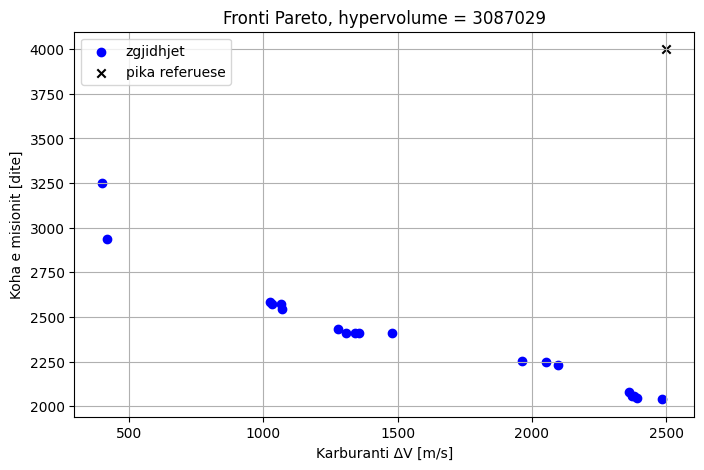

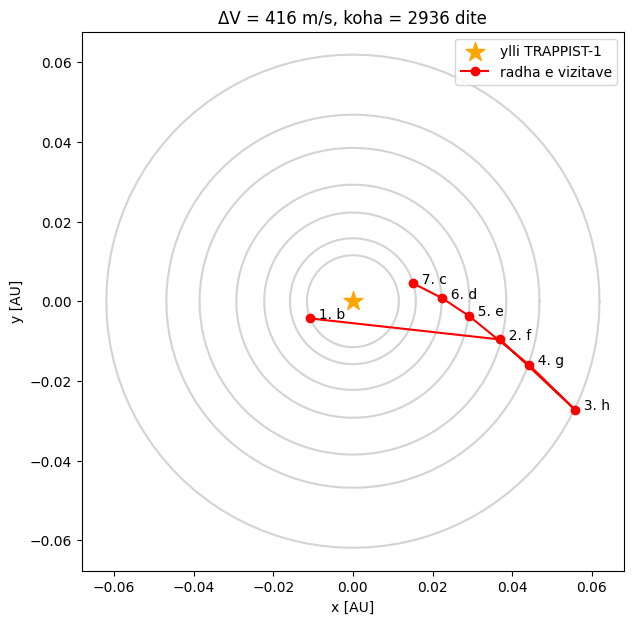

Zgjidhje te ruajtura ne submission.json: 19


In [9]:
   import plots

   # 1) grafiku i frontit Pareto
   plots.plot_pareto(front)

   # 2) radha e vizitave per zgjidhjen me te balancuar
   knee = max(front, key=lambda f: (2500 - f[0]) * (4000 - f[1]))
   plots.plot_tour(knee[2])

   # 3) ruajme zgjidhjet per ESA
   n = solver.save_submission(front)
   print("Zgjidhje te ruajtura ne submission.json:", n)

In [10]:
%%writefile compare.py
"""
Krahasimi i algoritmeve (analiza DAA):

  1. Random Search    - plane udhetimi krejt te rastit (pa asnje strategji)
  2. Greedy           - Beam Search me gjeresi 1 (merr gjithmone vetem me te mirin)
  3. Beam Search W=4  - mban 4 rruget me te mira ne cdo nivel
  4. Beam Search W=8  - mban 8 rruget me te mira (algoritmi yne kryesor)

Per secilin masim: hypervolume (cilesia), numrin e zgjidhjeve dhe kohen.
"""
import random
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import problem
import solver


def random_search(n=20000, seed=0):
    """Gjeneron n vektore krejt te rastit dhe mban ata qe jane te pranueshem."""
    rng = random.Random(seed)
    tours = []
    for _ in range(n):
        x = [rng.uniform(problem.LB[i], problem.UB[i]) for i in range(27)]
        x += [float(s) for s in rng.sample(range(7), 7)]     # radhe e rastit e planeteve
        dv, T, eq, ineq = problem.fitness(x)
        if eq == 0 and ineq <= 0:
            tours.append((dv, T, x))
    return tours


def _beam(args):
    tcap, width = args
    return solver.beam_search(tcap, width=width)


def run_beam(width, tcaps):
    """Ekzekuton Beam Search me gjeresine `width` per te gjithe kufijte kohore `tcaps`."""
    with Pool() as pool:
        results = pool.map(_beam, [(t, width) for t in tcaps])
    return [t for r in results for t in r]


def run_all(tcaps, beam8_tours=None, beam8_minutes=None):
    """Kthen nje liste rreshtash: (emri, hypervolume, zgjidhje ne front, minuta).
    Nese Beam W=8 eshte ekzekutuar me pare (hapi 5), jepi rezultatet qe te mos rillogaritet."""
    rows = []

    start = time.time()
    tours = random_search()
    rows.append(("Random Search", tours, (time.time() - start) / 60))
    print("Random Search: gati")

    for width, name in [(1, "Greedy (W=1)"), (4, "Beam Search (W=4)")]:
        start = time.time()
        tours = run_beam(width, tcaps)
        rows.append((name, tours, (time.time() - start) / 60))
        print(name + ": gati")

    if beam8_tours is None:
        start = time.time()
        beam8_tours = run_beam(8, tcaps)
        beam8_minutes = (time.time() - start) / 60
    rows.append(("Beam Search (W=8)", beam8_tours, beam8_minutes))

    table = []
    for name, tours, minutes in rows:
        front = solver.pareto_front(tours)
        table.append((name, round(solver.hypervolume(front)), len(front), round(minutes, 1)))
    return table


def print_table(table):
    print(f"{'Algoritmi':<20}{'Hypervolume':>14}{'Zgjidhje':>10}{'Koha (min)':>12}")
    print("-" * 56)
    for name, hv, n, minutes in table:
        print(f"{name:<20}{hv:>14,}{n:>10}{minutes:>12}")


def plot_table(table):
    names = [r[0] for r in table]
    hvs = [r[1] for r in table]
    times = [r[3] for r in table]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.bar(names, hvs, color="steelblue")
    ax1.set_title("Cilesia: hypervolume (me shume = me mire)")
    ax1.tick_params(axis="x", rotation=20)
    for i, v in enumerate(hvs):
        ax1.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

    ax2.bar(names, times, color="darkorange")
    ax2.set_title("Koha e ekzekutimit (minuta)")
    ax2.tick_params(axis="x", rotation=20)
    for i, v in enumerate(times):
        ax2.text(i, v, str(v), ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.savefig("krahasimi.png")
    plt.show()


Writing compare.py


Random Search: gati
Greedy (W=1): gati
Beam Search (W=4): gati
Algoritmi              Hypervolume  Zgjidhje  Koha (min)
--------------------------------------------------------
Random Search                    0        14         0.5
Greedy (W=1)             2,972,146         6         5.9
Beam Search (W=4)        3,048,492        14        10.2
Beam Search (W=8)        3,087,029        22        13.6


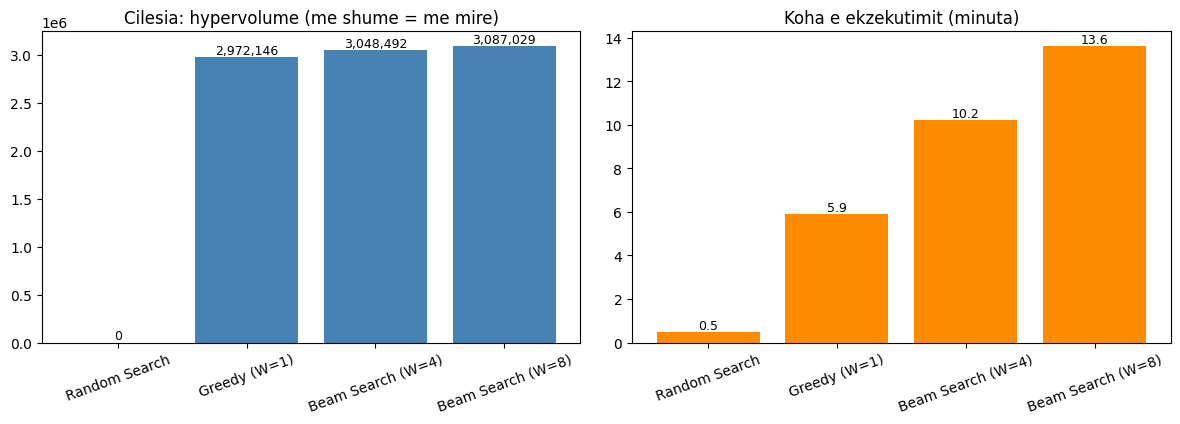

In [11]:
   import compare

   tabela = compare.run_all(tcaps, beam8_tours=tours, beam8_minutes=13.6)
   compare.print_table(tabela)
   compare.plot_table(tabela)